> # <center><font color='red'>**Used Car Market Trend Analysis (Car Dekho Data)**</font></center>

This project performs exploratory data analysis and visualization on Car Dekho used-car data to identify pricing patterns, market trends, depreciation, and relationships between vehicle attributes. The analysis examines factors such as car age, mileage, fuel type, transmission, seller type, and ownership history that influence resale prices. The objective is to derive meaningful insights that support data-driven vehicle pricing, purchasing, selling, and inventory decisions.

>### **IMPORTING REQUIRED LIBRARIES & PACKAGES**



In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from os import dup

>### **IMPORTING AND READING THE DATASET**

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/1776311302-P3-Car Market Trends Analysis with Car Dekho Data.csv")

>### **1.** **DATA EXPLORATION AND QUALITY ASSESSMENT**




In [ ]:
#Dataset Dimensions

df.shape

(301, 9)

#### <font color='red'>**Note:** There are total 301 rows and 9 columns in the dataset before duplicate removal and data cleaning.</font>

In [ ]:
#Column Overview

df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='object')

In [ ]:
#Initial Data Preview
#Exploring first 5 rows of the dataset

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [ ]:
#Initial Data Preview
#Exploring last 5 rows of the dataset

df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


In [ ]:
#Duplicate Record Detection

duplicate_rows = df[df.duplicated(keep=False)]

print(f"Total duplicate rows found: {len(duplicate_rows)}")
duplicate_rows

Total duplicate rows found: 4


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [ ]:
#Duplicate Removal

df = df.drop_duplicates().copy()
print('Duplicates remaining',df.duplicated().sum())

Duplicates remaining 0


In [ ]:
#Data Types & Structure

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 299 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       299 non-null    object 
 1   Year           299 non-null    int64  
 2   Selling_Price  299 non-null    float64
 3   Present_Price  299 non-null    float64
 4   Kms_Driven     299 non-null    int64  
 5   Fuel_Type      299 non-null    object 
 6   Seller_Type    299 non-null    object 
 7   Transmission   299 non-null    object 
 8   Owner          299 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 23.4+ KB


In [ ]:
#Descriptive Statistics

df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.567887,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


#### <font color='red'>**Key Findings from Descriptive Statistics:**</font><br>


#### 1. Total Records: 299 vehicles remain after duplicate removal and data cleaning.
#### 2. Manufacturing Year: Vehicles in the dataset were manufactured between 2003 and 2018.
#### 3. Average Selling Price: The overall average selling price is approximately ₹4.59 lakhs.
#### 4. Minimum Selling Price: The lowest selling price is ₹0.10 lakh (₹10,000).
#### 5. Maximum Selling Price: The highest selling price is ₹35 lakhs.
#### 6. Average Present Price: The overall average present price is approximately ₹7.54 lakhs.
#### 7. Minimum Present Price: The lowest present price is ₹0.32 lakh (₹32,000).
#### 8. Maximum Present Price: The highest present price is ₹92.60 lakhs.
#### 9. Average Vehicle Usage: Vehicles have been driven an average of approximately 36,917 km.
#### 10. Ownership: The average number of previous owners is approximately 0.04, with the majority of vehicles having 0 previous owners.




In [ ]:
# Missing Value Assessment

df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


#### <font color='red'>**Note:** There are no missing or null values in the dataset.</font>

>### **2.** **KEY DERIVED METRICS AND FEATURES**



**<font color='yellow'>CAR AGE:</font>**<br>

Note: Here we took 2018(latest manufacturing year) as Reference Year beacuse this is historical Car Dekho data

In [ ]:
df['Car_Age'] = 2018 - df['Year']
df[['Car_Name', 'Car_Age']]

,Car_Name,Car_Age
0,ritz,4
1,sx4,5
2,ciaz,1
3,wagon r,7
4,swift,4
...,...,...
296,city,2
297,brio,3
298,city,9
299,city,1


**<font color='yellow'>DEPRECIATION AMOUNT (PRESENT PRICE - SELLING PRICE):</font>**

In [ ]:
df['Depreciation_Amount'] = (df['Present_Price'] - df['Selling_Price']).round(2)
df[['Car_Name', 'Present_Price', 'Selling_Price', 'Depreciation_Amount']]

,Car_Name,Present_Price,Selling_Price,Depreciation_Amount
0,ritz,5.59,3.35,2.24
1,sx4,9.54,4.75,4.79
2,ciaz,9.85,7.25,2.60
3,wagon r,4.15,2.85,1.30
4,swift,6.87,4.60,2.27
...,...,...,...,...
296,city,11.60,9.50,2.10
297,brio,5.90,4.00,1.90
298,city,11.00,3.35,7.65
299,city,12.50,11.50,1.00


**<font color='yellow'>DEPRECIATION %:</font>**

In [ ]:
df['Depreciation_%'] = (((df['Present_Price'] - df['Selling_Price']) / df['Present_Price']) * 100).round(2)
df[['Car_Name', 'Present_Price', 'Selling_Price', 'Depreciation_Amount', 'Depreciation_%']]

,Car_Name,Present_Price,Selling_Price,Depreciation_Amount,Depreciation_%
0,ritz,5.59,3.35,2.24,40.07
1,sx4,9.54,4.75,4.79,50.21
2,ciaz,9.85,7.25,2.60,26.40
3,wagon r,4.15,2.85,1.30,31.33
4,swift,6.87,4.60,2.27,33.04
...,...,...,...,...,...
296,city,11.60,9.50,2.10,18.10
297,brio,5.90,4.00,1.90,32.20
298,city,11.00,3.35,7.65,69.55
299,city,12.50,11.50,1.00,8.00


**<font color='yellow'>PRICE RETENTION %:</font>**

In [ ]:
df['Price Retention %'] = ((df['Selling_Price'] / df['Present_Price']) * 100).round(2)
df[['Car_Name', 'Present_Price', 'Selling_Price', 'Price Retention %']]

,Car_Name,Present_Price,Selling_Price,Price Retention %
0,ritz,5.59,3.35,59.93
1,sx4,9.54,4.75,49.79
2,ciaz,9.85,7.25,73.60
3,wagon r,4.15,2.85,68.67
4,swift,6.87,4.60,66.96
...,...,...,...,...
296,city,11.60,9.50,81.90
297,brio,5.90,4.00,67.80
298,city,11.00,3.35,30.45
299,city,12.50,11.50,92.00


> ### **3. EXPLORATORY DATA ANALYSIS (EDA)**

> ### **3.1 UNIVARIATE ANALYSIS**

###**<font color="orange">Top 10 Car Models by Number of Listings</font>**
**TO FIND: Which car models have the highest number of listings in the dataset?**

,Car_Model,Number_of_Listings
0,city,26
1,corolla altis,16
2,verna,14
3,brio,10
4,fortuner,10
5,ciaz,9
6,i20,9
7,innova,9
8,grand i10,8
9,Royal Enfield Classic 350,7


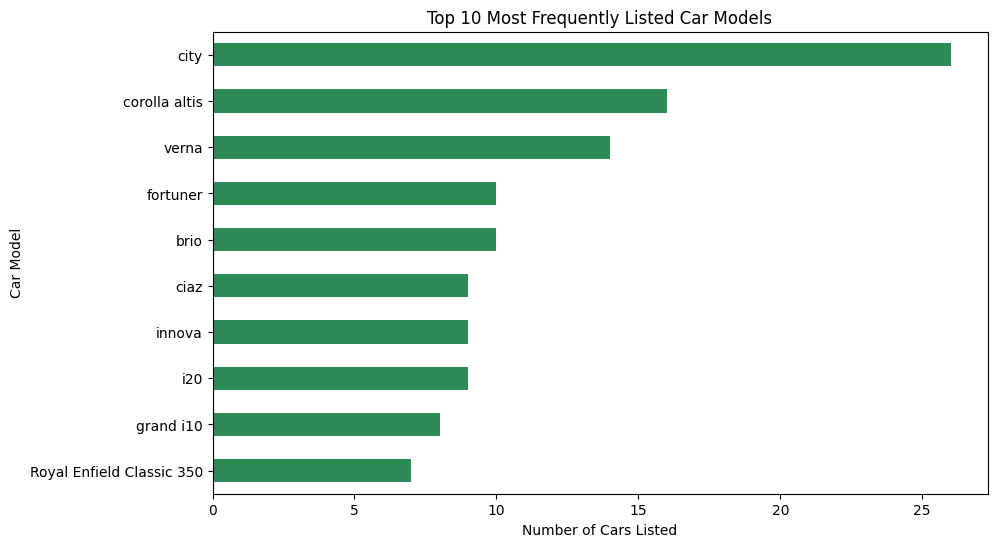

In [ ]:
car_sales_count = (df['Car_Name'].value_counts().reset_index())

car_sales_count.columns = ['Car_Model', 'Number_of_Listings']

display(car_sales_count.head(10))

#Visualization:

top_10_cars = df['Car_Name'].value_counts().head(10)

top_10_cars.sort_values().plot(kind='barh', figsize=(10, 6), color='seagreen')

plt.title('Top 10 Most Frequently Listed Car Models')
plt.xlabel('Number of Cars Listed')
plt.ylabel('Car Model')
plt.show()

**<font color='red'>Analytical Statement:<br> The Maruti Suzuki City has the highest number of listings (26), followed by Corolla Altis (16) and Verna (14), indicating stronger representation of these models in the dataset.</font>**

###**<font color="orange">Number of Cars Listed by Fuel Type</font>**
**TO FIND: Which fuel type has the highest number of listed cars?**

,Fuel_Type,Number_of_Cars_Listed
0,Petrol,239
1,Diesel,58
2,CNG,2


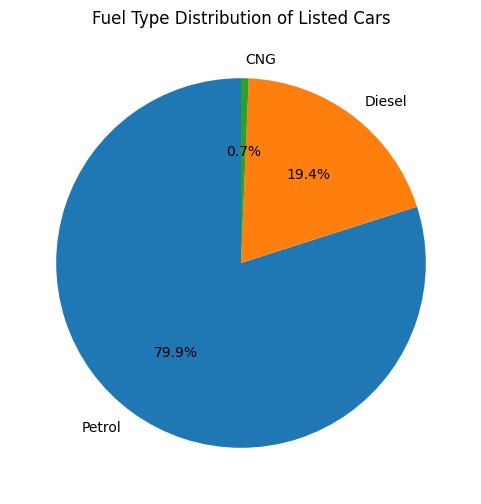

In [ ]:
fuel_count = (df['Fuel_Type'].value_counts().reset_index())

fuel_count.columns = ['Fuel_Type', 'Number_of_Cars_Listed']

display(fuel_count)

#Visualization:

plt.figure(figsize=(6, 6))

plt.pie(fuel_count['Number_of_Cars_Listed'], labels=fuel_count['Fuel_Type'], autopct='%1.1f%%',startangle=90)

plt.title('Fuel Type Distribution of Listed Cars')

plt.show()

**<font color='red'>Analytical Statement:<br> The above graph shows that Petrol cars dominate the listings, accounting for 239 vehicles (79.9%), followed by Diesel with 58 vehicles (19.4%), and CNG cars being the least common with only 2 listings (0.7%).</font>**

###**<font color="orange">Number of Cars Listed by Seller Type</font>**
**TO FIND: Which seller type accounts for the highest number of car listings?**

,Seller_Type,Number_of_Cars_Listed
0,Dealer,193
1,Individual,106


Text(0, 0.5, 'Number of Cars')

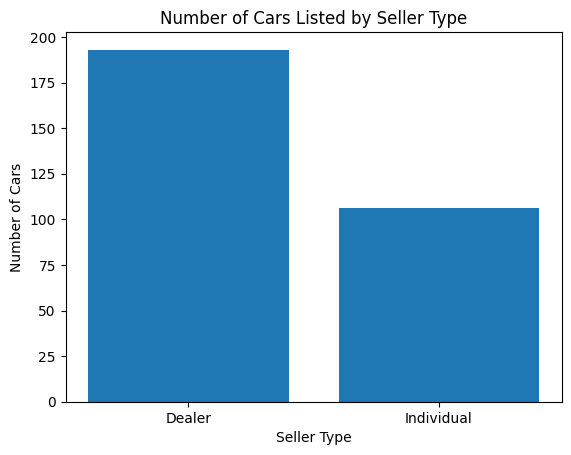

In [ ]:
seller_type_count = (df['Seller_Type'].value_counts().reset_index())

seller_type_count.columns = ['Seller_Type', 'Number_of_Cars_Listed']

display(seller_type_count)

#Visualization:

plt.bar(x=seller_type_count['Seller_Type'], height=seller_type_count['Number_of_Cars_Listed'])
plt.title('Number of Cars Listed by Seller Type')
plt.xlabel('Seller Type')
plt.ylabel('Number of Cars')

**<font color='red'>Analytical Statement:<br> The above chart shows that 'Dealer' is the predominant seller type, with 193 car listings, significantly outnumbering 'Individual' sellers who have 106 listings. This suggests that the majority of used car transactions in this dataset are facilitated through dealerships.</font>**

###**<font color="orange">Number of Cars Listed by Transmission Type</font>**
**TO FIND: Which transmission type is more common among the listed cars?**

,Transmission,Number_of_Cars
0,Manual,260
1,Automatic,39


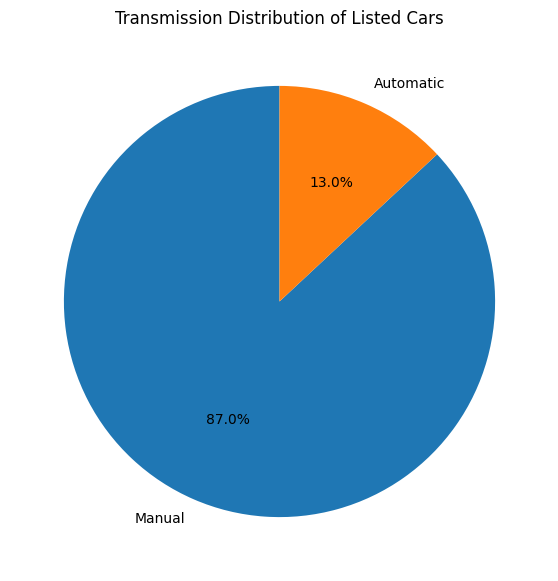

In [69]:
transmission_count = (df['Transmission'].value_counts().reset_index())

transmission_count.columns = ['Transmission', 'Number_of_Cars']

display(transmission_count)

#Visualization:

plt.figure(figsize=(7, 7))

plt.pie(transmission_count['Number_of_Cars'], labels=transmission_count['Transmission'], autopct='%1.1f%%', startangle=90)

plt.title('Transmission Distribution of Listed Cars')

plt.show()

**<font color='red'>Analytical Statement:<br>The graph clearly illustrates that manual transmission cars are significantly more prevalent in the dataset, accounting for 260 listings (87%), while automatic transmission cars represent a much smaller portion with 39 listings (13%).</font>**

###**<font color="orange">Number of Cars Listed by Previous Owner Count</font>**
**TO FIND: How are cars distributed based on the number of previous owners?**

,Number_of_Owners,Number_of_Cars
0,0,288
1,1,10
2,3,1


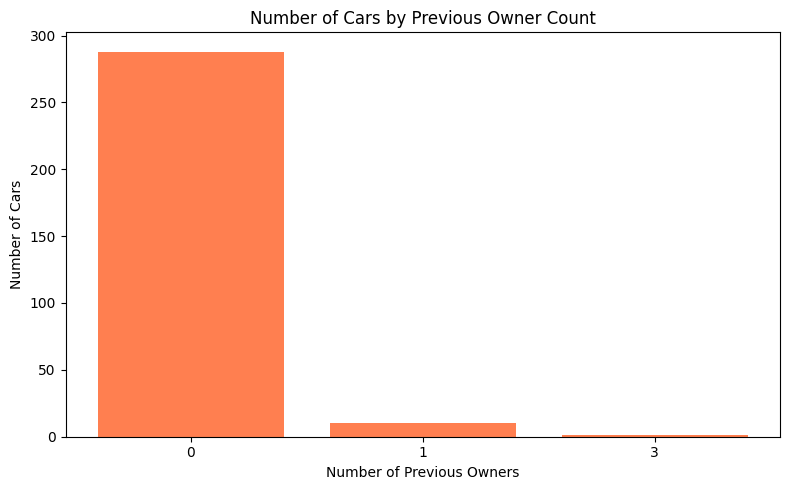

In [71]:
owner_count = (df['Owner'].value_counts().sort_index().reset_index())

owner_count.columns = ['Number_of_Owners', 'Number_of_Cars']

display(owner_count)

#Visualization:

plt.figure(figsize=(8, 5))

plt.bar(owner_count['Number_of_Owners'].astype(str), owner_count['Number_of_Cars'], color='coral')

plt.title('Number of Cars by Previous Owner Count')
plt.xlabel('Number of Previous Owners')
plt.ylabel('Number of Cars')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The graph reveals that the vast majority of cars in the dataset (288 out of 299) have had no previous owners (Owner = 0), indicating a high proportion of first-owner vehicles. A smaller number of cars (10) have had one previous owner, and only a single car has had three previous owners.</font>**

> ### **3.2 BIVARIATE ANALYSIS**

###**<font color="orange">Average Selling Price By Car Model</font>**
**TO FIND: Does car model affect the average selling price?**

,Car_Model,Avg_Selling_Price
0,land cruiser,35.00
1,fortuner,18.25
2,innova,12.78
3,creta,11.80
4,elantra,11.60
...,...,...
93,Hero Hunk,0.20
94,Hero Super Splendor,0.20
95,Hero Ignitor Disc,0.20
96,Bajaj ct 100,0.18


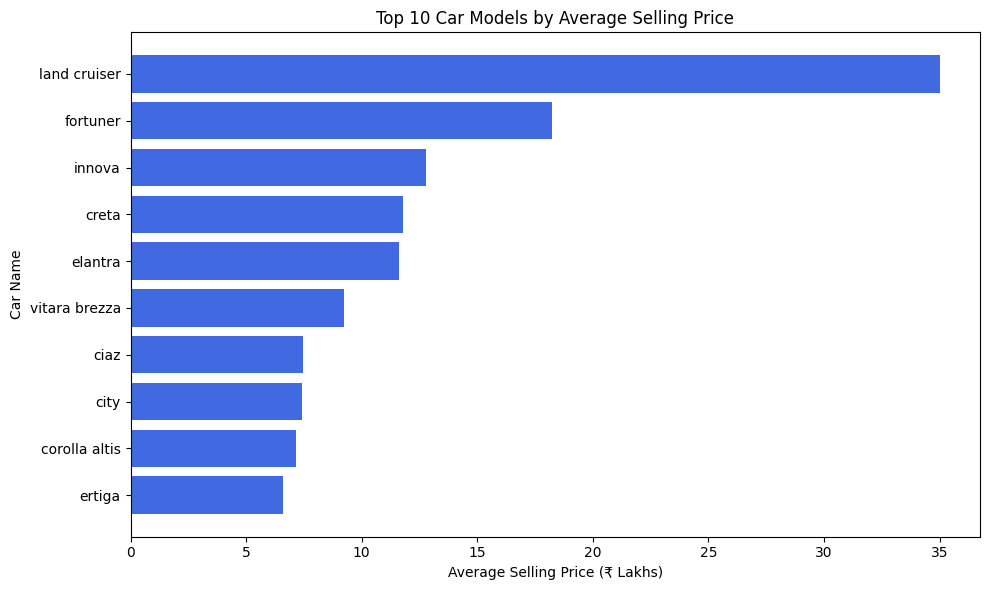

In [72]:
avg_sp_by_car_model = df.groupby('Car_Name')['Selling_Price'].mean().sort_values(ascending=False).round(2).reset_index()

avg_sp_by_car_model.columns = ['Car_Model', 'Avg_Selling_Price']

display(avg_sp_by_car_model)

#Visualization:

top_10_avg_price = avg_sp_by_car_model.head(10).sort_values('Avg_Selling_Price',ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(top_10_avg_price['Car_Model'], top_10_avg_price['Avg_Selling_Price'], color='royalblue')

plt.title('Top 10 Car Models by Average Selling Price')
plt.xlabel('Average Selling Price (₹ Lakhs)')
plt.ylabel('Car Name')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>Car model has a significant impact on average selling price, with Land Cruiser having the highest average selling price at ₹35 lakhs, followed by Fortuner at ₹18.25 lakhs and Innova at ₹12.78 lakhs. 'Ertiga' has the lowest average selling price among the top 10 at ₹6.58 lakhs.</font>**

###**<font color="orange">Average Selling Price by Car Age (Reference Year-Manufacturing Year)</font>**

<font color='red'>Note: Since the dataset contains historical Car Dekho data with 2018 as the latest manufacturing year, 2018 is used as the reference year for calculating Car Age.</font><br>

**TO FIND: Does car age affect the average selling price?**

,Car_Age,Avg_Selling_Price
0,0,9.25
1,1,6.21
2,2,5.16
3,3,5.64
4,4,4.76
5,5,3.54
6,6,3.84
7,7,2.38
8,8,5.26
9,9,2.82


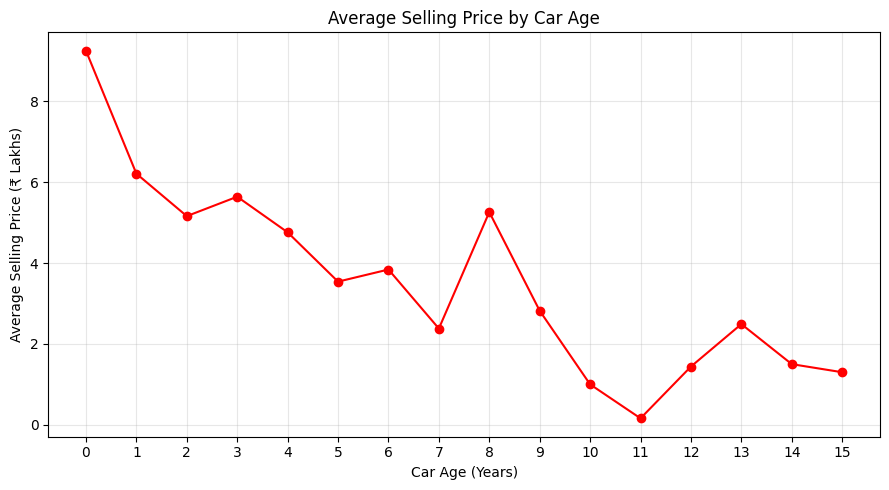

In [73]:
avg_sp_by_car_age = (df.groupby('Car_Age')['Selling_Price'].mean().round(2).reset_index())

avg_sp_by_car_age.columns = ['Car_Age','Avg_Selling_Price']

# Sort by car age
avg_sp_by_car_age = avg_sp_by_car_age.sort_values('Car_Age')

display(avg_sp_by_car_age)

# Visualization:

plt.figure(figsize=(9, 5))

plt.plot(avg_sp_by_car_age['Car_Age'],avg_sp_by_car_age['Avg_Selling_Price'],marker='o',color='red')

plt.title('Average Selling Price by Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Average Selling Price (₹ Lakhs)')

plt.xticks(avg_sp_by_car_age['Car_Age'])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph demonstrates a clear inverse relationship between car age and average selling price: as a car's age increases, its average selling price generally decreases. This indicates that newer cars command higher prices, while older cars experience significant depreciation.</font>**

###**<font color="orange">Kms Driven vs Selling Price</font>**
**TO FIND: Does higher car usage result in a lower selling price?**

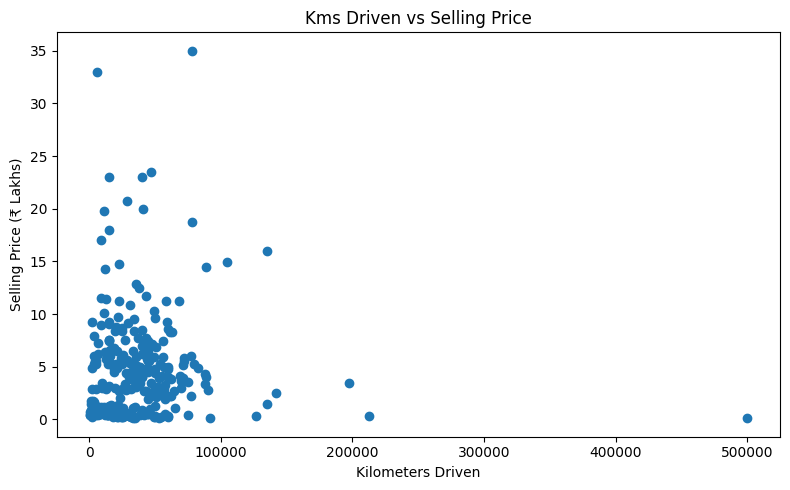

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Kms_Driven'], df['Selling_Price'])

plt.title('Kms Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (₹ Lakhs)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The scatter plot of 'Kms Driven vs Selling Price' does not show a clear linear relationship between kilometers driven and selling price. While there is a general tendency for selling prices to decrease with higher kilometers driven, there's significant variability, especially at lower mileage, suggesting other factors strongly influence the selling price.</font>**

###**<font color="orange">Average Selling Price by Mileage Range</font>**
**TO FIND: How does average selling price vary across different mileage ranges?**

In [ ]:
df['Mileage_Range'] = np.select(
    [
        df['Kms_Driven'] <= 20000,
        df['Kms_Driven'] <= 40000,
        df['Kms_Driven'] <= 60000,
        df['Kms_Driven'] <= 80000
    ],
    ['0–20K', '20K–40K', '40K–60K', '60K–80K'],
    default='80K+'
)

,Mileage_Range,Avg_Selling_Price
0,0–20K,4.07
1,20K–40K,4.43
2,40K–60K,4.81
3,60K–80K,6.48
4,80K+,4.88


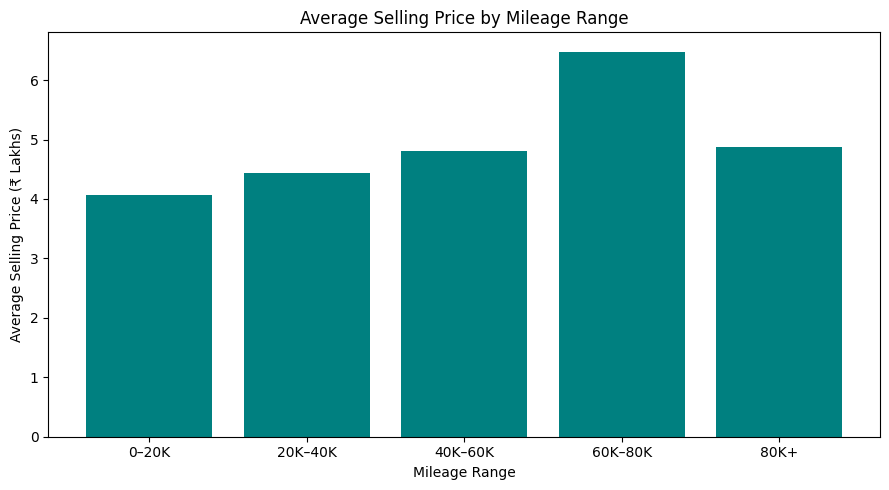

In [74]:
avg_sp_by_mileage = (df.groupby('Mileage_Range', observed=True)['Selling_Price'].mean().round(2).reset_index())

avg_sp_by_mileage.columns = ['Mileage_Range','Avg_Selling_Price']

display(avg_sp_by_mileage)

#Visualization:

plt.figure(figsize=(9, 5))

plt.bar(avg_sp_by_mileage['Mileage_Range'],avg_sp_by_mileage['Avg_Selling_Price'], color='teal')

plt.title('Average Selling Price by Mileage Range')
plt.xlabel('Mileage Range')
plt.ylabel('Average Selling Price (₹ Lakhs)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br> The above graph reveals a non-linear relationship between mileage range and average selling price. Initially, the average selling price tends to increase as mileage goes from '0–20K' to '60K–80K', with the highest average price observed in the '60K–80K' range at ₹6.48 lakhs. However, for cars with '80K+' mileage, the average selling price decreases to ₹4.88 lakhs.</font>**

###**<font color="orange">High-Mileage vs Low-Mileage Vehicles</font>**
**TO FIND: Do low-mileage cars have a higher average selling price than high-mileage cars?**

In [ ]:
df['Mileage_Category'] = np.where(
    df['Kms_Driven'] <= 40000,
    'Low Mileage',
    'High Mileage'
)

,Mileage_Category,Avg_Selling_Price
0,High Mileage,5.18
1,Low Mileage,4.24


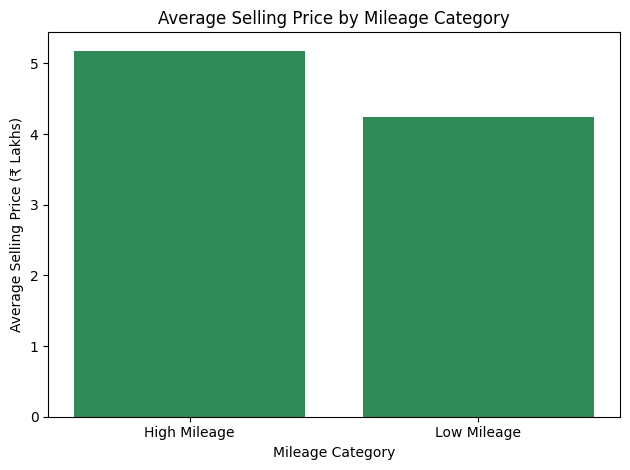

In [94]:
avg_sp_by_mileage_category = (df.groupby('Mileage_Category')['Selling_Price'].mean().round(2).reset_index())

avg_sp_by_mileage_category.columns = ['Mileage_Category','Avg_Selling_Price']

display(avg_sp_by_mileage_category)

#Visualization:

plt.bar(avg_sp_by_mileage_category['Mileage_Category'], avg_sp_by_mileage_category['Avg_Selling_Price'], color='seagreen')
plt.title('Average Selling Price by Mileage Category')
plt.xlabel('Mileage Category')
plt.ylabel('Average Selling Price (₹ Lakhs)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br> Contrary to general expectation, the above analysis shows that 'High Mileage' cars (Kms_Driven > 40,000) have a slightly higher average selling price of ₹5.18 lakhs compared to 'Low Mileage' cars (Kms_Driven <= 40,000) which average ₹4.24 lakhs.</font>**

###**<font color="orange">Kms Driven vs Depreciation</font>**
**TO FIND:  Does higher car usage result in greater depreciation?**

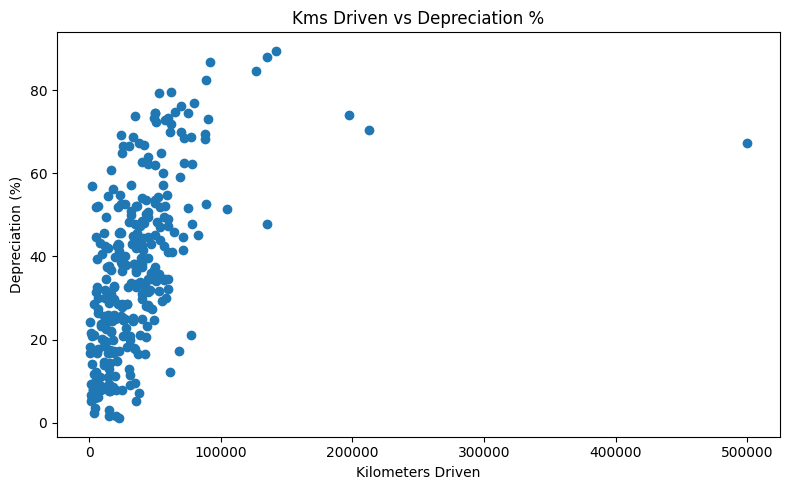

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Kms_Driven'], df['Depreciation_%'])

plt.title('Kms Driven vs Depreciation %')
plt.xlabel('Kilometers Driven')
plt.ylabel('Depreciation (%)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above scatter plot illustrates a general positive correlation between kilometers driven and depreciation percentage. As the kilometers driven increase, the depreciation percentage also tends to rise, indicating that higher car usage typically results in greater depreciation.</font>**

###**<font color="orange">Average Depreciation by Mileage Range</font>**
**TO FIND: How does average depreciation vary across different mileage ranges?**

,Mileage_Range,Avg_Depreciation_%
0,0–20K,22.47
1,20K–40K,35.33
2,40K–60K,44.79
3,60K–80K,55.06
4,80K+,70.05


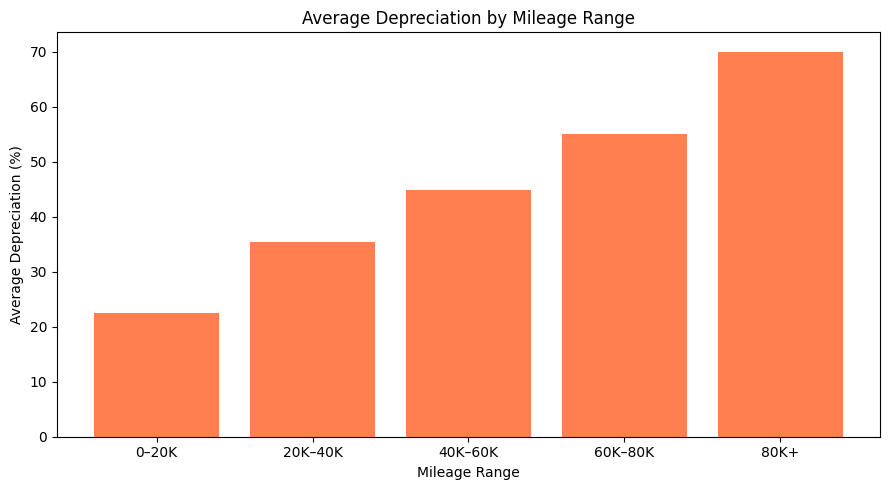

In [76]:
avg_depreciation_by_mileage = (df.groupby('Mileage_Range')['Depreciation_%'].mean().round(2).reset_index())

avg_depreciation_by_mileage.columns = ['Mileage_Range','Avg_Depreciation_%']

display(avg_depreciation_by_mileage)

#Visualization:

plt.figure(figsize=(9, 5))

plt.bar(avg_depreciation_by_mileage['Mileage_Range'], avg_depreciation_by_mileage['Avg_Depreciation_%'], color='coral')

plt.title('Average Depreciation by Mileage Range')
plt.xlabel('Mileage Range')
plt.ylabel('Average Depreciation (%)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph clearly demonstrates a direct relationship between mileage range and average depreciation. As the kilometers driven increase across the mileage ranges, the average depreciation percentage consistently rises, with cars in the '80K+' mileage category experiencing the highest average depreciation at 70.05%.</font>**

###**<font color="orange">Average Selling Price by Fuel Type</font>**
**TO FIND: Which fuel type has the highest average selling price?**

,Fuel_Type,Selling_Price
0,CNG,3.10
1,Diesel,10.10
2,Petrol,3.26


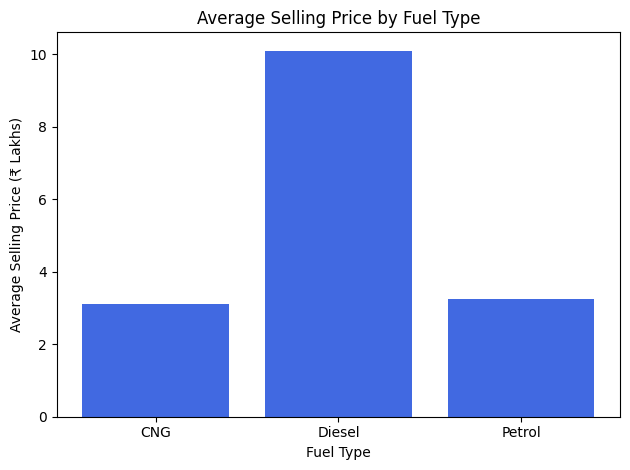

In [78]:
avg_sp_by_fuel_type = (df.groupby('Fuel_Type')['Selling_Price'].mean().round(2).reset_index())
display(avg_sp_by_fuel_type)

#Visualization:

plt.bar(avg_sp_by_fuel_type['Fuel_Type'], avg_sp_by_fuel_type['Selling_Price'], color='royalblue')

plt.title('Average Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price (₹ Lakhs)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph indicates that Diesel cars command the highest average selling price at ₹10.10 lakhs, significantly higher than Petrol cars, which average ₹3.26 lakhs. CNG cars have the lowest average selling price at ₹3.10 lakhs.</font>**

###**<font color="orange">Average Depreciation by Fuel Type</font>**
**TO FIND: Which fuel type retains its value better in the used-car market?**

,Fuel_Type,Avg_Depreciation_%
0,CNG,49.02
1,Diesel,32.22
2,Petrol,37.58


Text(0.5, 0, 'Fuel Type')

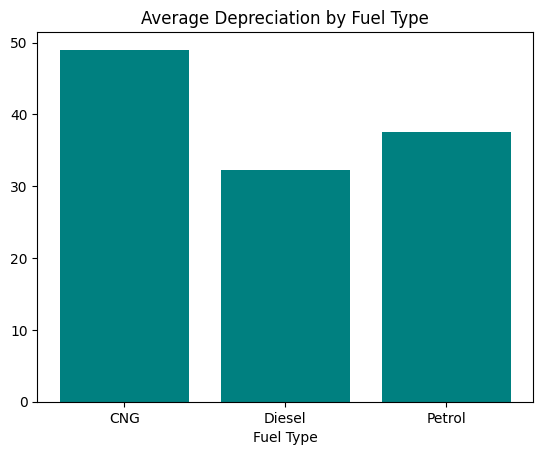

In [88]:
avg_depreciation_by_fuel_type = (df.groupby('Fuel_Type')['Depreciation_%'].mean().round(2).reset_index())

avg_depreciation_by_fuel_type.columns = ['Fuel_Type','Avg_Depreciation_%']

display(avg_depreciation_by_fuel_type)

#Visualization:

plt.bar(avg_depreciation_by_fuel_type['Fuel_Type'], avg_depreciation_by_fuel_type['Avg_Depreciation_%'], color='teal')

plt.title('Average Depreciation by Fuel Type')
plt.xlabel('Fuel Type')

**<font color='red'>Analytical Statement:<br>The above graph reveals that Diesel cars retain their value best in the used-car market, showing the lowest average depreciation at 32.22%. Petrol cars follow with an average depreciation of 37.58%, while CNG cars experience the highest depreciation at 49.02%.</font>**

###**<font color="orange">Average Selling Price by Seller Type</font>**
**TO FIND: Do dealer-sold cars have different average selling prices compared with individually sold cars?**

,Seller_Type,Selling_Price
0,Dealer,6.63
1,Individual,0.87


Text(0, 0.5, 'Average Selling Price')

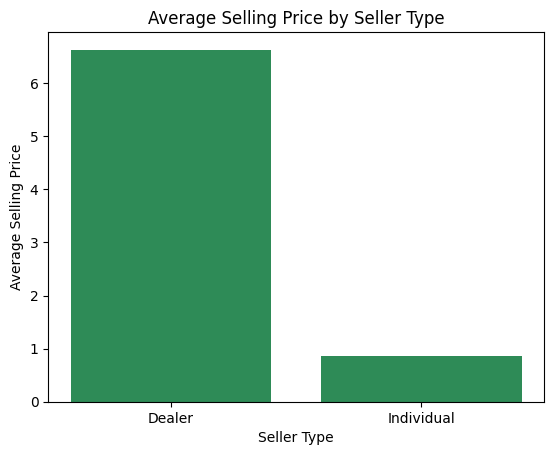

In [80]:
avg_sp_by_seller_type = (df.groupby('Seller_Type')['Selling_Price'].mean().round(2).reset_index())

display(avg_sp_by_seller_type)

#Visualization:

plt.bar(x=avg_sp_by_seller_type['Seller_Type'], height=avg_sp_by_seller_type['Selling_Price'], color='seagreen')
plt.title('Average Selling Price by Seller Type')
plt.xlabel('Seller Type')
plt.ylabel('Average Selling Price')

**<font color='red'>Analytical Statement:<br>The above graph clearly shows a significant difference in average selling prices between seller types. Dealer-sold cars have a substantially higher average selling price of ₹6.63 lakhs, compared to individually sold cars which average ₹0.87 lakhs.</font>**

###**<font color="orange">Average Selling Price by Transmission Type</font>**
**TO FIND: Do automatic cars command a higher average resale price than manual cars?**

,Transmission,Selling_Price
0,Automatic,9.07
1,Manual,3.92


Text(0, 0.5, 'Average Selling Price')

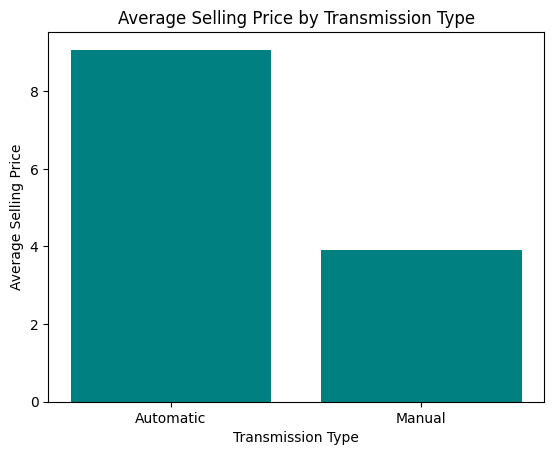

In [89]:
avg_sp_by_transmission_type = (df.groupby('Transmission')['Selling_Price'].mean().round(2).reset_index())

display(avg_sp_by_transmission_type)

#Visualization:

plt.bar(x=avg_sp_by_transmission_type['Transmission'], height=avg_sp_by_transmission_type['Selling_Price'], color='teal')
plt.title('Average Selling Price by Transmission Type')
plt.xlabel('Transmission Type')
plt.ylabel('Average Selling Price')

**<font color='red'>Analytical Statement:<br>The above graph indicates that automatic transmission cars command a significantly higher average selling price of ₹9.07 lakhs compared to manual transmission cars, which average ₹3.92 lakhs. This suggests that automatic cars generally have a greater resale value in this market.</font>**

###**<font color="orange">Average Depreciation by Transmission Type</font>**
**TO FIND: Which transmission type retains more of its value?**

,Transmission,Avg_Depreciation_%
0,Automatic,36.36
1,Manual,36.66


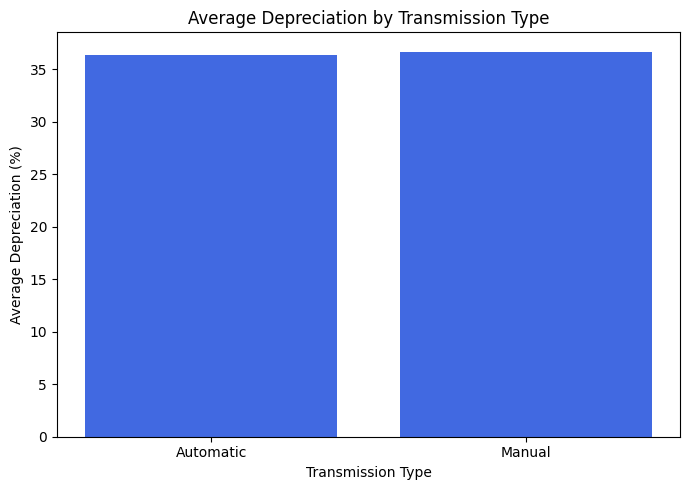

In [90]:
avg_depreciation_by_transmission_type = (df.groupby('Transmission')['Depreciation_%'].mean().round(2).reset_index())

avg_depreciation_by_transmission_type.columns = ['Transmission','Avg_Depreciation_%']

display(avg_depreciation_by_transmission_type)

#Visualization:

plt.figure(figsize=(7, 5))

plt.bar(avg_depreciation_by_transmission_type['Transmission'], avg_depreciation_by_transmission_type['Avg_Depreciation_%'], color='royalblue')

plt.title('Average Depreciation by Transmission Type')
plt.xlabel('Transmission Type')
plt.ylabel('Average Depreciation (%)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph reveals a negligible difference in value retention between transmission types. Automatic cars have an average depreciation of 36.36%, while manual cars show a slightly higher average depreciation of 36.66%. Both types retain their value almost equally.</font>**

###**<font color="orange">Average Selling Price by Number of Previous Owners</font>**
**TO FIND: Does the number of previous owners affect the average selling price?**

,Number_of_Owners,Avg_Selling_Price
0,0,4.69
1,1,1.97
2,3,2.50


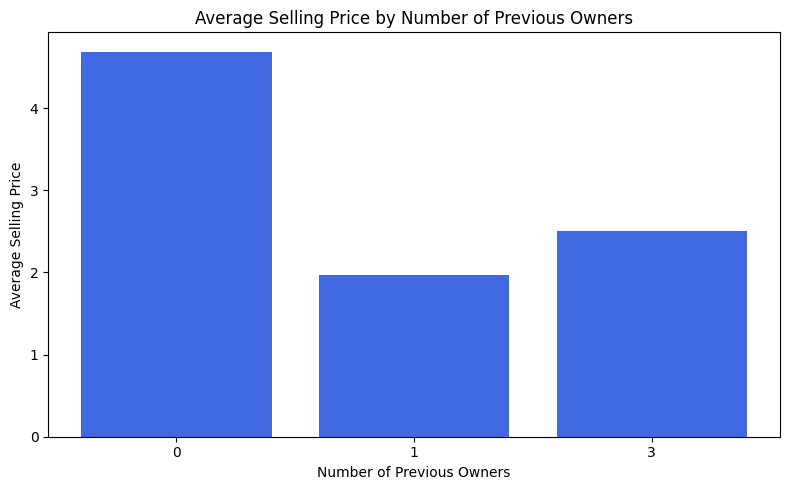

In [84]:
avg_sp_by_owner = (df.groupby('Owner')['Selling_Price'].mean().round(2).reset_index())

avg_sp_by_owner.columns = ['Number_of_Owners','Avg_Selling_Price']

display(avg_sp_by_owner)

#Visualization:

plt.figure(figsize=(8, 5))

plt.bar(
    avg_sp_by_owner['Number_of_Owners'].astype(str),
    avg_sp_by_owner['Avg_Selling_Price'], color='royalblue'
)

plt.title('Average Selling Price by Number of Previous Owners')
plt.xlabel('Number of Previous Owners')
plt.ylabel('Average Selling Price')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph indicates that the number of previous owners generally affects the average selling price. Cars with no previous owners command the highest average selling price at ₹4.69 lakhs. The price significantly drops to ₹1.97 lakhs for cars with one previous owner. Although cars with three previous owners show a slightly higher average selling price (₹2.50 lakhs) than those with one owner, this could be due to a very small sample size for the '3 owners' category, making the trend of decreasing price with more owners generally hold true.</font>**

###**<font color="orange">Average Depreciation by Number of Previous Owners</font>**
**TO FIND: Does having more previous owners correspond to greater depreciation?**

,Number_of_Owners,Avg_Depreciation_%
0,0,35.83
1,1,54.18
2,3,89.46


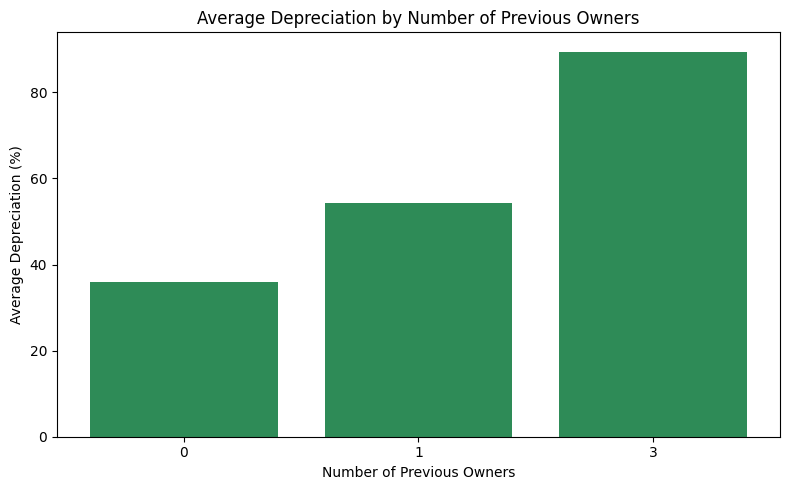

In [91]:
avg_depreciation_by_owner = (df.groupby('Owner')['Depreciation_%'].mean().round(2).reset_index())

avg_depreciation_by_owner.columns = ['Number_of_Owners','Avg_Depreciation_%']

display(avg_depreciation_by_owner)

#Visualization:

plt.figure(figsize=(8, 5))

plt.bar(
    avg_depreciation_by_owner['Number_of_Owners'].astype(str),
    avg_depreciation_by_owner['Avg_Depreciation_%'], color='seagreen'
)

plt.title('Average Depreciation by Number of Previous Owners')
plt.xlabel('Number of Previous Owners')
plt.ylabel('Average Depreciation (%)')

plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above graph strongly suggests that having more previous owners corresponds to greater depreciation. Cars with no previous owners show the lowest average depreciation at 35.83%. This percentage significantly increases to 54.18% for cars with one previous owner and further to 89.46% for cars with three previous owners, indicating a clear trend of increasing depreciation with each additional owner.</font>**

> ### **4. CORRELATION ANALYSIS**

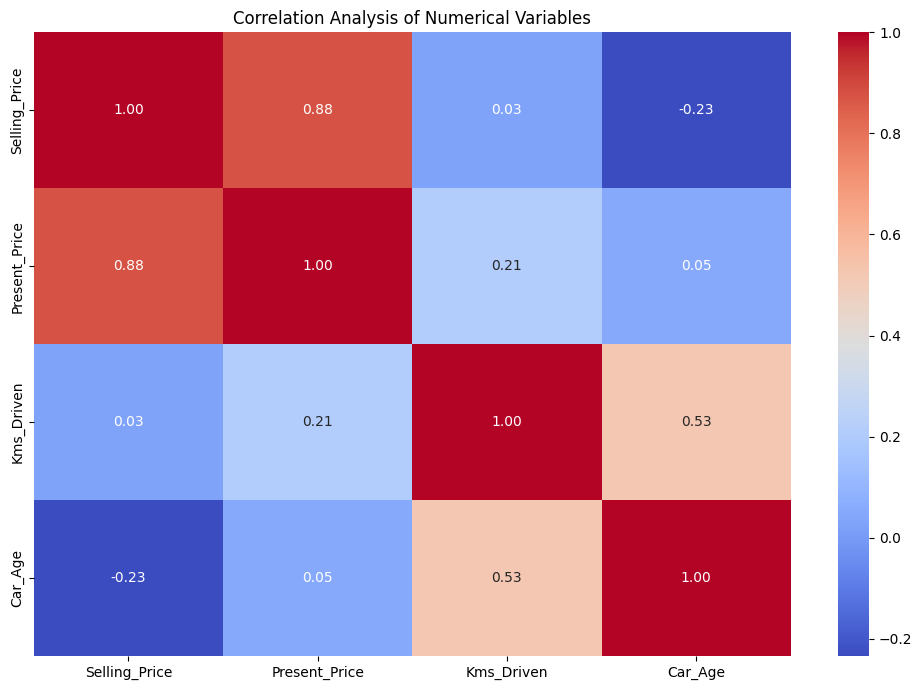

In [ ]:
numeric_cols = [
    'Selling_Price',
    'Present_Price',
    'Kms_Driven',
    'Car_Age',
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',fmt='.2f')

plt.title('Correlation Analysis of Numerical Variables')
plt.tight_layout()
plt.show()

**<font color='red'>Analytical Statement:<br>The above correlation matrix reveals strong positive correlations between 'Selling_Price' and 'Present_Price' (0.88), indicating that the current market price is a major determinant of the selling price. 'Kms_Driven' has a moderate positive correlation with 'Car_Age' (0.53) and a weak positive correlation with 'Present_Price' (0.21). 'Car_Age' shows a weak negative correlation with 'Selling_Price' (-0.23), suggesting that older cars tend to have lower selling prices.</font>**

> # <center><font color='blue'>**Overall Conclusion and Key Findings**</font></center>

Our comprehensive analysis of the used car market data has revealed several significant insights:

*   **Market Dominance by Specific Models & Fuel Types**: The dataset is heavily weighted towards certain models like the Maruti Suzuki City, Corolla Altis, and Verna. Petrol cars overwhelmingly dominate the listings (79.9%), followed by Diesel (19.4%), with CNG being a minor segment.
*   **Seller Type**: Dealers are the primary sellers, accounting for a significantly higher number of listings compared to individual sellers, suggesting a strong dealership-driven market.
*   **Transmission Type**: Manual transmission cars are far more prevalent (87%) than automatic cars (13%).
*   **Ownership**: The vast majority of cars are first-owner vehicles, with a sharp decline in listings for cars with one or more previous owners.

*   **Impact of Car Model on Price**: Car model significantly influences selling price, with premium models like the Land Cruiser commanding the highest average prices.
*   **Car Age and Depreciation**: There is a clear inverse relationship between car age and average selling price, indicating that newer cars sell for more. Correspondingly, 'Car_Age' shows a negative correlation with 'Selling_Price', confirming that older cars tend to depreciate more.
*   **Mileage and Price/Depreciation**: While the 'Kms Driven vs Selling Price' scatter plot did not show a strong linear relationship, further analysis of mileage ranges revealed a more complex pattern: average selling price initially increases with mileage up to the 60K–80K range, then decreases for '80K+' mileage. Conversely, average depreciation consistently rises with increasing mileage ranges, with cars in the '80K+' category experiencing the highest average depreciation (70.05%).
*   **Fuel Type and Price/Depreciation**: Diesel cars command the highest average selling prices and demonstrate the best value retention with the lowest average depreciation. Petrol cars have lower average selling prices and moderate depreciation, while CNG cars have the lowest average selling prices and highest depreciation.
*   **Seller Type and Price**: Dealer-sold cars have a substantially higher average selling price than individually sold cars.
*   **Transmission Type and Price/Depreciation**: Automatic cars have a significantly higher average selling price than manual cars, indicating their higher resale value. However, the difference in average depreciation between automatic and manual transmission types is negligible.
*   **Previous Owners and Price/Depreciation**: The number of previous owners directly impacts selling price and depreciation. Cars with no previous owners command the highest average selling prices and exhibit the lowest average depreciation. Each additional owner generally leads to a decrease in selling price and a substantial increase in depreciation, reinforcing the value of first-owner vehicles.

*   **Overall Correlations**: The correlation analysis highlighted a strong positive relationship between 'Selling_Price' and 'Present_Price', emphasizing that the current market price is the primary driver of the selling price. 'Kms_Driven' shows a moderate positive correlation with 'Car_Age' but only a weak positive correlation with 'Present_Price', while 'Car_Age' has a weak negative correlation with 'Selling_Price'.